# 06 · Avaliação no conjunto de teste

Avalia no conjunto de teste os nove modelos do notebook 05c (três arquiteturas × três sementes). O teste não foi usado em nenhuma etapa anterior, nem no treinamento nem na escolha dos hiperparâmetros.

As métricas (precisão, revocação, F1-score e AUC-ROC) são reportadas como média e desvio-padrão entre as sementes. A matriz de confusão, as curvas ROC e a análise de erros usam os modelos da semente 42.

A GPU é opcional.

## 1. Configuração

In [ ]:
import os, json, glob
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, precision_recall_curve)
from google.colab import drive

drive.mount('/content/drive')

DATA_DIR     = '/content/drive/MyDrive/TCC-Exoplanetas'
VIEWS_DIR    = f'{DATA_DIR}/views_v2'
MODELS_DIR   = f'{DATA_DIR}/modelos'
SEMENTES_DIR = f'{MODELS_DIR}/sementes'
FIG_DIR      = f'{DATA_DIR}/figuras'
os.makedirs(FIG_DIR, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
SEMENTES = [42, 7, 123]
print('device:', device)

Mounted at /content/drive
device: cuda


In [ ]:
d = np.load(f'{DATA_DIR}/dataset.npz')
Xg_test, Xl_test, y_test = d['Xg_test'], d['Xl_test'], d['y_test'].astype(int)
print('teste:', Xg_test.shape, '| positivos:', y_test.mean().round(3))

# Configuracoes vencedoras
cfg_path, res_path = f'{MODELS_DIR}/config_final.json', f'{MODELS_DIR}/busca_resultados.json'
if os.path.exists(cfg_path):
    cf = json.load(open(cfg_path))
    VENCEDORAS = {s: {'lr': v['lr'], 'ramo': v['ramo']} for s, v in cf.items()}
else:
    res = json.load(open(res_path)); VENCEDORAS = {}
    for slug in ['cnn1d', 'bilstm', 'transformer']:
        cands = {k: v for k, v in res.items() if v['slug'] == slug}
        VENCEDORAS[slug] = cands[min(cands, key=lambda k: cands[k]['melhor_val'])]['cfg']
for s, c in VENCEDORAS.items():
    print(f'  {s:12s} lr={c["lr"]}  {c["ramo"]}')

teste: (670, 2001) | positivos: 0.379
  cnn1d        lr=0.001  {'base': 16}
  bilstm       lr=0.001  {'hidden': 32, 'camadas': 1}
  transformer  lr=0.0003  {'d_model': 64, 'camadas': 2}


## 2. Conferência do conjunto de teste

O `dataset.npz` guarda os nomes dos KOIs de cada conjunto. A célula confere se os rótulos batem com os do catálogo e se nenhuma estrela do teste aparece no treino.

In [ ]:
assert 'koi_test' in d.files, 'dataset.npz sem nomes de KOIs: rode novamente a Parte B do Notebook 03.'
koi_teste = d['koi_test'].astype(str)

labels = pd.read_csv(f'{DATA_DIR}/koi_labels.csv').set_index('kepoi_name')
assert np.array_equal(labels.loc[koi_teste, 'label'].to_numpy(), y_test), 'Rotulos do teste nao conferem!'
assert not set(d['kepid_test']) & set(d['kepid_train']), 'Estrela do teste presente no treino!'
print('OK — identidade verificada. KOIs de teste:', len(koi_teste),
      '| estrelas de teste:', len(np.unique(d['kepid_test'])))

OK — identidade verificada. KOIs de teste: 670 | estrelas de teste: 584


## 3. Carregamento dos modelos

In [ ]:
class DoisRamos(nn.Module):
    def __init__(self, fabrica_ramo, p_dropout=0.3):
        super().__init__()
        self.ramo_global = fabrica_ramo(); self.ramo_local = fabrica_ramo()
        d_ = self.ramo_global.out_dim
        self.cabeca = nn.Sequential(
            nn.Linear(2 * d_, 64), nn.ReLU(), nn.Dropout(p_dropout), nn.Linear(64, 1))
    def forward(self, g, l):
        return self.cabeca(torch.cat([self.ramo_global(g), self.ramo_local(l)], 1)).squeeze(-1)

class RamoCNN(nn.Module):
    def __init__(self, base=16):
        super().__init__()
        c1, c2, c3 = base, base * 2, base * 4
        self.net = nn.Sequential(
            nn.Conv1d(1, c1, 5, padding=2), nn.ReLU(), nn.MaxPool1d(5, 2),
            nn.Conv1d(c1, c2, 5, padding=2), nn.ReLU(), nn.MaxPool1d(5, 2),
            nn.Conv1d(c2, c3, 5, padding=2), nn.ReLU(), nn.AdaptiveMaxPool1d(1))
        self.out_dim = c3
    def forward(self, x): return self.net(x).squeeze(-1)

class RamoBiLSTM(nn.Module):
    def __init__(self, hidden=64, camadas=2):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden, num_layers=camadas, batch_first=True,
                            bidirectional=True, dropout=0.1 if camadas > 1 else 0.0)
        self.out_dim = 2 * hidden
    def forward(self, x):
        s, _ = self.lstm(x.transpose(1, 2)); return s.mean(dim=1)

def codificacao_posicional(comprimento, dim, device):
    pos = torch.arange(comprimento, device=device).unsqueeze(1).float()
    i   = torch.arange(dim, device=device).unsqueeze(0).float()
    ang = pos / torch.pow(torch.tensor(10000.0, device=device), (2 * (i // 2)) / dim)
    pe = torch.zeros(comprimento, dim, device=device)
    pe[:, 0::2] = torch.sin(ang[:, 0::2]); pe[:, 1::2] = torch.cos(ang[:, 1::2])
    return pe.unsqueeze(0)

class RamoTransformer(nn.Module):
    def __init__(self, d_model=64, nhead=4, camadas=2, stride=8):
        super().__init__()
        self.embed = nn.Conv1d(1, d_model, kernel_size=2 * stride + 1, stride=stride, padding=stride)
        camada = nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=128,
                                            dropout=0.1, batch_first=True)
        self.encoder = nn.TransformerEncoder(camada, camadas); self.out_dim = d_model
    def forward(self, x):
        z = self.embed(x).transpose(1, 2)
        z = z + codificacao_posicional(z.size(1), z.size(2), z.device)
        return self.encoder(z).mean(dim=1)

CLASSES = {'cnn1d': RamoCNN, 'bilstm': RamoBiLSTM, 'transformer': RamoTransformer}
NOMES   = {'cnn1d': 'CNN 1D', 'bilstm': 'BiLSTM', 'transformer': 'Transformer'}

In [ ]:
@torch.no_grad()
def prever(slug, semente):
    """Carrega o checkpoint de (arquitetura, semente) e devolve as probabilidades no teste."""
    cfg = VENCEDORAS[slug]
    modelo = DoisRamos(lambda: CLASSES[slug](**cfg['ramo'])).to(device)
    modelo.load_state_dict(torch.load(f'{SEMENTES_DIR}/{slug}_seed{semente}.pt',
                                      map_location=device))
    modelo.eval()
    probs = []
    for i in range(0, len(y_test), 256):
        g = torch.from_numpy(Xg_test[i:i+256]).float().unsqueeze(1).to(device)
        l = torch.from_numpy(Xl_test[i:i+256]).float().unsqueeze(1).to(device)
        probs.append(torch.sigmoid(modelo(g, l)).cpu().numpy())
    return np.concatenate(probs)

# probabilidades de todas as combinacoes
PROBS = {slug: {s: prever(slug, s) for s in SEMENTES} for slug in VENCEDORAS}
print('predicoes calculadas para', len(PROBS) * len(SEMENTES), 'modelos')

predicoes calculadas para 9 modelos


## 4. Resultados no teste

Média e desvio-padrão entre as três sementes, com limiar de decisão de 0,5. Base da Tabela 4 do TCC.

In [ ]:
LIMIAR = 0.5

def metricas(y, p, limiar=LIMIAR):
    yp = (p >= limiar).astype(int)
    return {'Precision': precision_score(y, yp, zero_division=0),
            'Recall':    recall_score(y, yp, zero_division=0),
            'F1':        f1_score(y, yp, zero_division=0),
            'AUC-ROC':   roc_auc_score(y, p)}

linhas = []
for slug in VENCEDORAS:
    ms = [metricas(y_test, PROBS[slug][s]) for s in SEMENTES]
    linha = {'Arquitetura': NOMES[slug]}
    for k in ['Precision', 'Recall', 'F1', 'AUC-ROC']:
        vals = np.array([m[k] for m in ms])
        linha[k] = f'{vals.mean():.4f} ± {vals.std(ddof=1):.4f}'
    linhas.append(linha)

tabela = pd.DataFrame(linhas)
display(tabela)
tabela.to_csv(f'{DATA_DIR}/resultados_teste.csv', index=False)
print('Salvo: resultados_teste.csv')

,Arquitetura,Precision,Recall,F1,AUC-ROC
0,CNN 1D,0.8190 ± 0.0074,0.9199 ± 0.0127,0.8665 ± 0.0024,0.9568 ± 0.0011
1,BiLSTM,0.7940 ± 0.0418,0.8307 ± 0.0297,0.8113 ± 0.0228,0.9346 ± 0.0144
2,Transformer,0.8124 ± 0.0293,0.8675 ± 0.0298,0.8383 ± 0.0044,0.9501 ± 0.0016


Salvo: resultados_teste.csv


### 4.1 Valores por semente

Para cada métrica e cada par de arquiteturas, compara as faixas entre o menor e o maior valor obtidos com as três sementes. Faixas que se sobrepõem indicam desempenho equivalente; faixas disjuntas, uma diferença consistente entre as sementes testadas.

In [ ]:
por_semente = pd.DataFrame([
    {'Arquitetura': NOMES[slug], 'Semente': s, **metricas(y_test, PROBS[slug][s])}
    for slug in VENCEDORAS for s in SEMENTES])
display(por_semente.round(4))
por_semente.to_csv(f'{DATA_DIR}/resultados_teste_por_semente.csv', index=False)
print('Salvo: resultados_teste_por_semente.csv\n')

faixas = por_semente.groupby('Arquitetura')[['Precision', 'Recall', 'F1', 'AUC-ROC']].agg(['min', 'max'])
display(faixas.round(4))

pares = [('CNN 1D', 'Transformer'), ('CNN 1D', 'BiLSTM'), ('Transformer', 'BiLSTM')]
for k in ['Precision', 'Recall', 'F1', 'AUC-ROC']:
    for a, b in pares:
        (amin, amax), (bmin, bmax) = faixas.loc[a, k], faixas.loc[b, k]
        sobrepoe = amin <= bmax and bmin <= amax
        print(f'{k:9s} {a:11s} x {b:11s}: ', 'sobrepoem (equivalentes)' if sobrepoe else 'DISJUNTAS')

,Arquitetura,Semente,Precision,Recall,F1,AUC-ROC
0,CNN 1D,42,0.8166,0.9291,0.8692,0.9558
1,CNN 1D,7,0.8273,0.9055,0.8647,0.9580
2,CNN 1D,123,0.8131,0.9252,0.8656,0.9564
3,BiLSTM,42,0.8104,0.8583,0.8337,0.9451
4,BiLSTM,7,0.7465,0.8346,0.7881,0.9182
5,BiLSTM,123,0.8252,0.7992,0.8120,0.9406
6,Transformer,42,0.8158,0.8543,0.8346,0.9484
7,Transformer,7,0.8398,0.8465,0.8431,0.9515
8,Transformer,123,0.7816,0.9016,0.8373,0.9504


Salvo: resultados_teste_por_semente.csv



Precision          Recall              F1         AUC-ROC        
                  min     max     min     max     min     max     min     max
Arquitetura                                                                  
BiLSTM         0.7465  0.8252  0.7992  0.8583  0.7881  0.8337  0.9182  0.9451
CNN 1D         0.8131  0.8273  0.9055  0.9291  0.8647  0.8692  0.9558  0.9580
Transformer    0.7816  0.8398  0.8465  0.9016  0.8346  0.8431  0.9484  0.9515

Precision CNN 1D      x Transformer:  sobrepoem (equivalentes)
Precision CNN 1D      x BiLSTM     :  sobrepoem (equivalentes)
Precision Transformer x BiLSTM     :  sobrepoem (equivalentes)
Recall    CNN 1D      x Transformer:  DISJUNTAS
Recall    CNN 1D      x BiLSTM     :  DISJUNTAS
Recall    Transformer x BiLSTM     :  sobrepoem (equivalentes)
F1        CNN 1D      x Transformer:  DISJUNTAS
F1        CNN 1D      x BiLSTM     :  DISJUNTAS
F1        Transformer x BiLSTM     :  DISJUNTAS
AUC-ROC   CNN 1D      x Transformer:  DISJUNTAS
AUC-ROC   CNN 1D      x BiLSTM     :  DISJUNTAS
AUC-ROC   Transformer x BiLSTM     :  DISJUNTAS


## 5. Matrizes de confusão (semente 42)

Figura 3 do TCC.

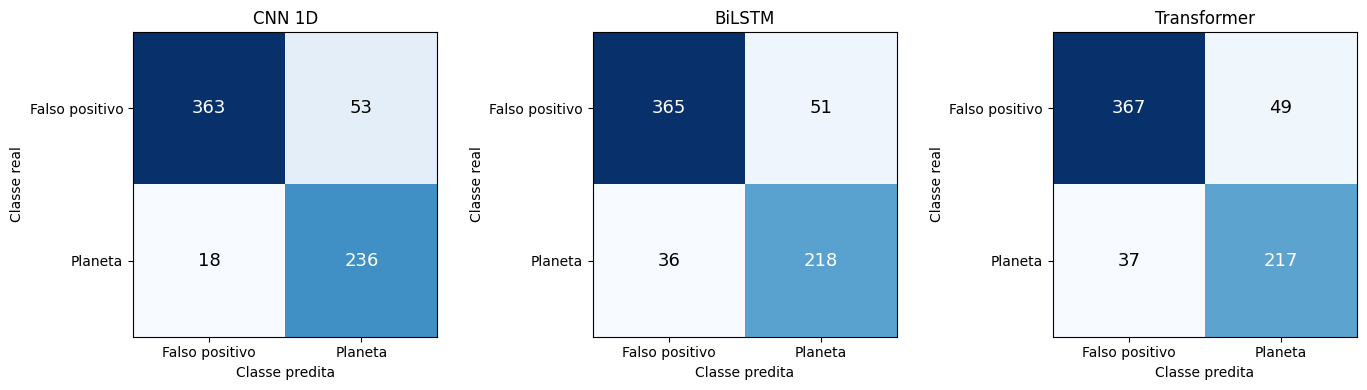

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, slug in zip(axes, VENCEDORAS):
    yp = (PROBS[slug][42] >= LIMIAR).astype(int)
    cm = confusion_matrix(y_test, yp)
    ax.imshow(cm, cmap='Blues')
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, str(v), ha='center', va='center',
                color='white' if v > cm.max() / 2 else 'black', fontsize=13)
    ax.set_title(NOMES[slug])
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Falso positivo', 'Planeta'])
    ax.set_yticks([0, 1]); ax.set_yticklabels(['Falso positivo', 'Planeta'])
    ax.set_xlabel('Classe predita'); ax.set_ylabel('Classe real')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/matrizes_confusao.png', dpi=300); plt.show()

## 6. Curvas ROC (semente 42)

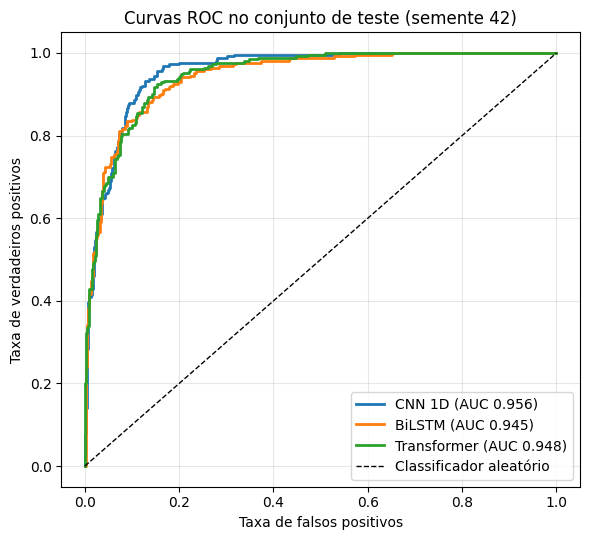

In [ ]:
plt.figure(figsize=(6, 5.5))
for slug in VENCEDORAS:
    p = PROBS[slug][42]
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2, label=f'{NOMES[slug]} (AUC {roc_auc_score(y_test, p):.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Classificador aleatório')
plt.xlabel('Taxa de falsos positivos'); plt.ylabel('Taxa de verdadeiros positivos')
plt.title('Curvas ROC no conjunto de teste (semente 42)')
plt.legend(loc='lower right'); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/curvas_roc.png', dpi=300); plt.show()

## 7. Revocação e precisão em função do limiar

O limiar de 0,5 é uma convenção. Como deixar de detectar um planeta é o erro mais custoso, o gráfico mostra quanto a revocação aumenta, e a precisão diminui, com limiares mais baixos.

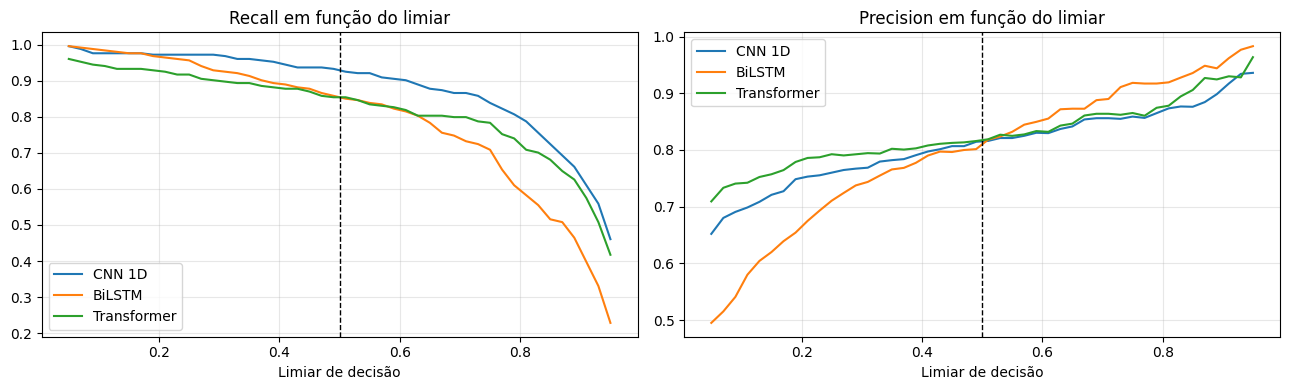

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
limiares = np.linspace(0.05, 0.95, 46)
for slug in VENCEDORAS:
    p = PROBS[slug][42]
    recs = [recall_score(y_test, (p >= t).astype(int), zero_division=0) for t in limiares]
    precs = [precision_score(y_test, (p >= t).astype(int), zero_division=0) for t in limiares]
    ax[0].plot(limiares, recs, label=NOMES[slug])
    ax[1].plot(limiares, precs, label=NOMES[slug])
ax[0].axvline(0.5, color='k', ls='--', lw=1); ax[0].set_title('Recall em função do limiar')
ax[1].axvline(0.5, color='k', ls='--', lw=1); ax[1].set_title('Precision em função do limiar')
for a in ax: a.set_xlabel('Limiar de decisão'); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/limiar.png', dpi=300); plt.show()

## 8. Análise de erros

Relaciona os erros de cada modelo com a profundidade do trânsito, o SNR e o período orbital de cada KOI, para verificar se eles se concentram em trânsitos rasos, sinais fracos ou períodos longos. A taxa de erro por quintil considera todos os KOIs do teste, planetas e falsos positivos (Figura 4 do TCC).

In [ ]:
labels_df = pd.read_csv(f'{DATA_DIR}/koi_labels.csv')

df = pd.DataFrame({'kepoi_name': koi_teste, 'y': y_test})
for slug in VENCEDORAS:
    df[f'prob_{slug}'] = PROBS[slug][42]
    df[f'acerto_{slug}'] = ((PROBS[slug][42] >= LIMIAR).astype(int) == y_test)

df = df.merge(labels_df[['kepoi_name', 'koi_depth', 'koi_model_snr', 'koi_period',
                         'koi_prad', 'kepler_name']], on='kepoi_name', how='left')
print('teste com metadados:', df.shape)
df.head()

teste com metadados: (670, 13)


,kepoi_name,y,prob_cnn1d,acerto_cnn1d,prob_bilstm,acerto_bilstm,prob_transformer,acerto_transformer,koi_depth,koi_model_snr,koi_period,koi_prad,kepler_name
0,K00028.01,0,0.000006,True,0.000477,True,0.000010,True,123521.0,2619.2,4.100870,82.46,NaN
1,K00044.01,0,0.614454,False,0.559036,False,0.966343,False,12643.7,1049.3,66.467462,11.97,NaN
2,K00045.01,0,0.003599,True,0.021212,True,0.001984,True,18887.0,394.7,6.397186,15.02,NaN
3,K00063.01,1,0.995342,True,0.952791,True,0.988558,True,3977.0,40.2,9.434142,5.73,Kepler-63 b
4,K00081.01,0,0.018958,True,0.521568,False,0.487821,True,1611.7,225.5,23.876114,10.45,NaN


SNR do modelo | limites dos quintis: ['3.1-15.5', '15.5-26.0', '26.0-48.2', '48.2-283.1', '283.1-7486.2']
Profundidade do trânsito (ppm) | limites dos quintis: ['4.5-165.3', '165.3-394.6', '394.6-966.1', '966.1-17890.2', '17890.2-824392.0']
Período orbital (dias) | limites dos quintis: ['0.4-1.5', '1.5-4.6', '4.6-11.3', '11.3-29.4', '29.4-614.4']


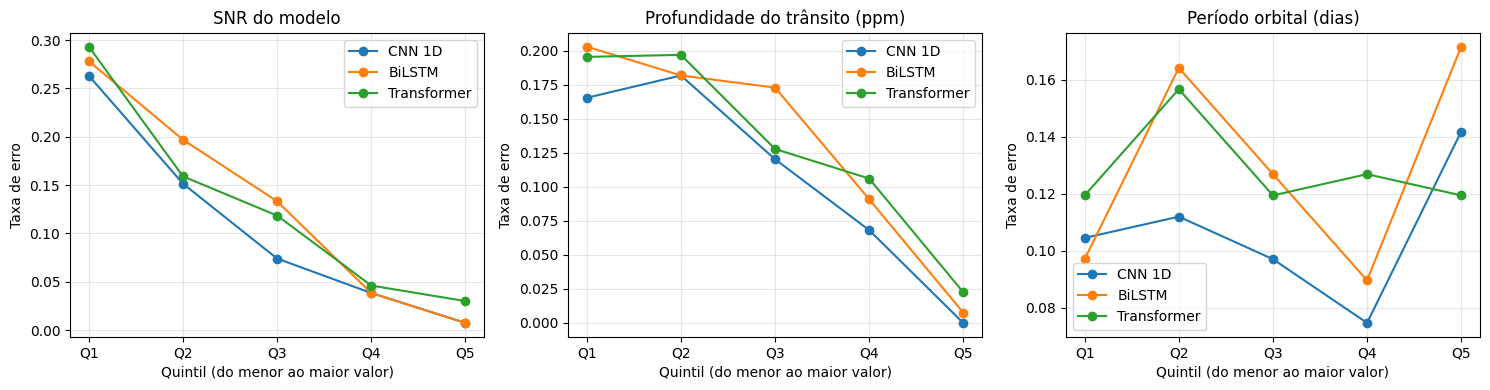

In [ ]:
# Taxa de erro por faixa de SNR e de profundidade
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

for eixo, coluna, titulo, log in [
        (ax[0], 'koi_model_snr', 'SNR do modelo', True),
        (ax[1], 'koi_depth',     'Profundidade do trânsito (ppm)', True),
        (ax[2], 'koi_period',    'Período orbital (dias)', True)]:
    dados = df.dropna(subset=[coluna]).copy()
    dados['faixa'] = pd.qcut(dados[coluna], q=5, duplicates='drop')
    for slug in VENCEDORAS:
        taxa = dados.groupby('faixa', observed=True)[f'acerto_{slug}'].apply(lambda s: 1 - s.mean())
        eixo.plot(range(len(taxa)), taxa.values, marker='o', label=NOMES[slug])
    # quintis rotulados Q1..Q5; os limites de cada quintil sao impressos para a legenda da figura
    eixo.set_xticks(range(len(taxa))); eixo.set_xticklabels([f'Q{i + 1}' for i in range(len(taxa))])
    print(titulo, '| limites dos quintis:', [f'{iv.left:.1f}-{iv.right:.1f}' for iv in taxa.index])
    eixo.set_title(titulo)
    eixo.set_xlabel('Quintil (do menor ao maior valor)'); eixo.set_ylabel('Taxa de erro')
    eixo.legend(); eixo.grid(alpha=0.3)

plt.tight_layout(); plt.savefig(f'{FIG_DIR}/erros_por_parametro.png', dpi=300); plt.show()

In [ ]:
# Falsos negativos do modelo representativo: planetas reais que passaram batido
for slug in VENCEDORAS:
    fn = df[(df.y == 1) & (~df[f'acerto_{slug}'])]
    print(f'\n=== {NOMES[slug]}: {len(fn)} falsos negativos ===')
    print(f"  profundidade mediana: {fn.koi_depth.median():.0f} ppm  "
          f"(vs {df[df.y==1].koi_depth.median():.0f} ppm em todos os planetas)")
    print(f"  SNR mediano: {fn.koi_model_snr.median():.1f}  "
          f"(vs {df[df.y==1].koi_model_snr.median():.1f})")
    cols = ['kepoi_name', 'kepler_name', 'koi_depth', 'koi_model_snr', 'koi_period']
    display(fn.nsmallest(5, f'prob_{slug}')[cols])


=== CNN 1D: 18 falsos negativos ===
  profundidade mediana: 245 ppm  (vs 464 ppm em todos os planetas)
  SNR mediano: 21.9  (vs 29.7)


,kepoi_name,kepler_name,koi_depth,koi_model_snr,koi_period
232,K01989.01,Kepler-1040 b,584.8,34.7,201.118319
196,K01671.01,Kepler-1763 b,60.5,21.3,1.480283
255,K02133.01,Kepler-91 b,396.8,63.6,6.246675
430,K04036.01,Kepler-1544 b,614.4,15.3,168.811330
156,K01241.02,Kepler-56 b,183.4,45.3,10.500771



=== BiLSTM: 36 falsos negativos ===
  profundidade mediana: 432 ppm  (vs 464 ppm em todos os planetas)
  SNR mediano: 21.8  (vs 29.7)


,kepoi_name,kepler_name,koi_depth,koi_model_snr,koi_period
183,K01581.01,Kepler-896 c,879.9,39.5,29.542257
173,K01529.02,Kepler-59 b,101.9,13.9,11.869314
430,K04036.01,Kepler-1544 b,614.4,15.3,168.811330
400,K03728.01,Kepler-1517 b,2211.0,56.4,5.546083
199,K01687.01,Kepler-928 b,455.5,30.6,3.932461



=== Transformer: 37 falsos negativos ===
  profundidade mediana: 296 ppm  (vs 464 ppm em todos os planetas)
  SNR mediano: 18.9  (vs 29.7)


,kepoi_name,kepler_name,koi_depth,koi_model_snr,koi_period
232,K01989.01,Kepler-1040 b,584.8,34.7,201.118319
118,K00952.05,Kepler-32 f,843.3,45.3,0.742958
313,K02851.01,Kepler-1985 b,356.8,13.9,3.420647
48,K00408.03,Kepler-150 e,742.2,32.3,30.826104
314,K02852.01,Kepler-1368 b,200.7,22.4,0.675650


In [ ]:
# Taxas de erro exatas por quintil (%), para o texto da secao 4.3
for coluna, titulo in [('koi_model_snr', 'SNR'), ('koi_depth', 'Profundidade'), ('koi_period', 'Periodo')]:
    dados = df.dropna(subset=[coluna]).copy()
    dados['faixa'] = pd.qcut(dados[coluna], q=5, duplicates='drop')
    tabela = pd.DataFrame({NOMES[s]: dados.groupby('faixa', observed=True)[f'acerto_{s}'].apply(lambda x: 100 * (1 - x.mean()))
                           for s in VENCEDORAS})
    tabela.index = [f'Q{i + 1} ({iv.left:.1f}-{iv.right:.1f})' for i, iv in enumerate(tabela.index)]
    print(f'\n{titulo}'); print(tabela.round(1).to_string())



SNR
                   CNN 1D  BiLSTM  Transformer
Q1 (3.1-15.5)        26.3    27.8         29.3
Q2 (15.5-26.0)       15.2    19.7         15.9
Q3 (26.0-48.2)        7.4    13.3         11.9
Q4 (48.2-283.1)       3.8     3.8          4.6
Q5 (283.1-7486.2)     0.8     0.8          3.0

Profundidade
                       CNN 1D  BiLSTM  Transformer
Q1 (4.5-165.3)           16.5    20.3         19.5
Q2 (165.3-394.6)         18.2    18.2         19.7
Q3 (394.6-966.1)         12.0    17.3         12.8
Q4 (966.1-17890.2)        6.8     9.1         10.6
Q5 (17890.2-824392.0)     0.0     0.8          2.3

Periodo
                 CNN 1D  BiLSTM  Transformer
Q1 (0.4-1.5)       10.4     9.7         11.9
Q2 (1.5-4.6)       11.2    16.4         15.7
Q3 (4.6-11.3)       9.7    12.7         11.9
Q4 (11.3-29.4)      7.5     9.0         12.7
Q5 (29.4-614.4)    14.2    17.2         11.9


In [ ]:
# Salva as predicoes completas para consulta posterior
df.to_csv(f'{DATA_DIR}/predicoes_teste.csv', index=False)
print('Salvo: predicoes_teste.csv')
print('Figuras salvas em:', FIG_DIR)

Salvo: predicoes_teste.csv
Figuras salvas em: /content/drive/MyDrive/TCC-Exoplanetas/figuras


## Arquivos gerados

- `resultados_teste.csv` e `resultados_teste_por_semente.csv`: métricas no teste;
- `predicoes_teste.csv`: probabilidades e acertos dos modelos da semente 42, com os parâmetros físicos de cada KOI;
- `figuras/`: matrizes de confusão, curvas ROC, gráfico do limiar e taxa de erro por parâmetro físico.